<a target="_blank" rel="noopener noreferrer" href="https://colab.research.google.com/github/Center-for-Computational-Psychiatry/course_nycpw/blob/main/tutorials/2026/tutorial00_model-fitting.ipynb">![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)</a>

# Fitting models to behavioral data
### New York Computational Psychiatry Workshop 2026

By [Shawn A. Rhoads, Ph.D.](https://shawnrhoadsphd.com/) ([Social Interaction & Neural Computation Lab](https://sinclaboratory.com/))

This tutorial is adapted from Shawn A. Rhoads' [PSYC 347 course](https://shawnrhoadsphd.com/gu-psyc-347) [[CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/)], the examples in the [pyEM package](https://github.com/shawnrhoads/pyEM), and the [Neuromatch Academy tutorials](https://github.com/NeuromatchAcademy/course-content) [[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)].

## Goals

1. Write a likelihood function and minimize it with a grid search and `scipy.optimize.minimize`
2. Distinguish descriptive models (linear regression) from generative models (Rescorla-Wagner), and simulate choices from the generative one
3. Fit Rescorla-Wagner to one agent and to many agents using MLE, then check parameter recovery
4. Fit hierarchical models by MAP with the EM algorithm in [pyEM](https://github.com/shawnrhoads/pyEM), and relate this to mixed-effects regression
5. Compare models with AIC, BIC, and log model evidence

Code cells that start with `# TODO` only contain comments. We will write them together during the session.

In [1]:
# On Colab, uncomment the next line to install pyEM
%pip install -q git+https://github.com/shawnrhoads/pyEM.git
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm
from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import norm
from statsmodels.regression.mixed_linear_model import MixedLM
from pyem import EMModel
from pyem.utils import plotting
from pyem.core.compare import ModelComparison

sns.set_theme(style="ticks", palette=["royalblue", "crimson"], rc={
    "font.size": 11,                      # annotations default to 11
    "axes.labelsize": 12, "axes.titlesize": 12,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 11,
    "lines.markersize": 10,               # scatter default s = 10**2 = 100
    "image.cmap": "RdBu_r",               # one diverging map, blue (low) to red (high)
    "axes.spines.top": False, "axes.spines.right": False,
})

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 1. Likelihood

A model with parameters $\theta$ assigns a probability to the data we observe. Read as a function of $\theta$, that probability is the likelihood, $\mathcal{L}(\theta) = P(\mathcal{D} \mid \theta)$. Multiplying many small probabilities underflows, so we add their logs instead. Optimizers are written to minimize, so we minimize the negative log-likelihood (NLL).

$$\hat\theta = \arg\min_\theta \; -\sum_{i=1}^{n} \log P(d_i \mid \theta)$$

In [4]:
np.log(.1)+np.log(.1)

np.float64(-4.605170185988091)

## 2. Maximum likelihood example using linear regression

We start with a model most people know:

$$
y_i = b_0 + b_1 x_i + \epsilon_i
$$

where:
$$
\epsilon_i \sim \mathcal{N}(0, \sigma^2)
$$

We simulate the data ourselves, so we know the true parameter values.

In [5]:
# TODO: simulate regression data
# 1. Make one random generator for the whole notebook: rng = np.random.default_rng(2026)
# 2. Set n = 100, b0_true = 2.4, b1_true = 1.6, sigma = 1.0
# 3. Draw x: n values from Uniform(0, 10)
# 4. Compute y = b0_true + b1_true * x + Normal(0, sigma) noise
# Defines: rng, n, b0_true, b1_true, sigma, x (100,), y (100,)
rng = np.random.default_rng(2026)
n = 100
b0_true = 2.4
b1_true = 1.6
sigma = 1
x = rng.uniform(0,10,n)
y = b0_true + b1_true * x + rng.normal(0, sigma, n)

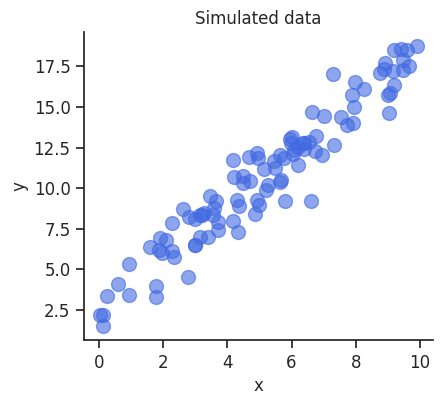

In [6]:
# plot the simulated data
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(x, y, alpha=0.6)
ax.set(xlabel="x", ylabel="y", title="Simulated data")
sns.despine()
plt.show()

If the errors are Gaussian, each observation has the likelihood:

$$P(y_i \mid b_0, b_1) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left(-\frac{(y_i - \hat y_i)^2}{2\sigma^2}\right), \qquad \hat y_i = b_0 + b_1 x_i$$

The NLL is the negative sum of its log over all $n$ points. Regression has a closed-form answer (ordinary least squares), but Rescorla-Wagner will not, so we practice the general method here. We fix $\sigma = 1$ because that is how we simulated the data.

In [7]:
# TODO: negative log-likelihood for the regression
# Define nll_lm(params, x, y):
#   1. Unpack b0, b1 from params
#   2. Predict y_hat = b0 + b1 * x
#   3. Score each y with norm.logpdf(y, loc=y_hat, scale=1)
#   4. Return the negative sum
# Then print nll_lm at [b0_true, b1_true] and at [0, 0]
# Defines: nll_lm(params (2,), x (n,), y (n,)) -> float
def nll_lm(params, x, y):
    b0, b1 = params
    y_hat = b0 + b1 * x
    nll = -np.sum(norm.logpdf(y, loc=y_hat, scale=1))
    return nll
print(nll_lm([b0_true, b1_true], x, y))
print(nll_lm([0, 0], x, y))

161.40683360403258
6832.482852147453


### Grid search

The simplest way to find the minimum is to try every pair of values on a grid and keep the pair with the lowest NLL. It usually works, but the number of evaluations grows as (points per parameter)<sup>(number of parameters)</sup>. Two parameters on a 60-point grid take 3,600 evaluations. Five parameters would take 777 million. Imagine what this might look like for more complex models.

In [10]:
# TODO: grid search
# 1. b0_grid = 60 values from -5 to 10; b1_grid = 60 values from -2 to 4
# 2. nll_grid = zeros of shape (60, 60), rows = b0, columns = b1
# 3. Loop over both grids and fill nll_grid with nll_lm
# 4. Find the minimum with np.unravel_index(nll_grid.argmin(), nll_grid.shape)
# 5. Store the best values as b0_grid_hat, b1_grid_hat
# Defines: b0_grid (60,), b1_grid (60,), nll_grid (60, 60), b0_grid_hat, b1_grid_hat
b0_grid = np.linspace(-5, 10, 60)
b1_grid = np.linspace(-2, 4, 60)
nll_grid = np.zeros((60, 60))
for i, b0_guess in enumerate(b0_grid):
    for j, b1_guess in enumerate(b1_grid):
        nll_grid[i, j] = nll_lm([b0_guess, b1_guess], x, y)

i_best, j_best = np.unravel_index(nll_grid.argmin(), nll_grid.shape)
b0_grid_hat, b1_grid_hat = b0_grid[i_best], b1_grid[j_best]

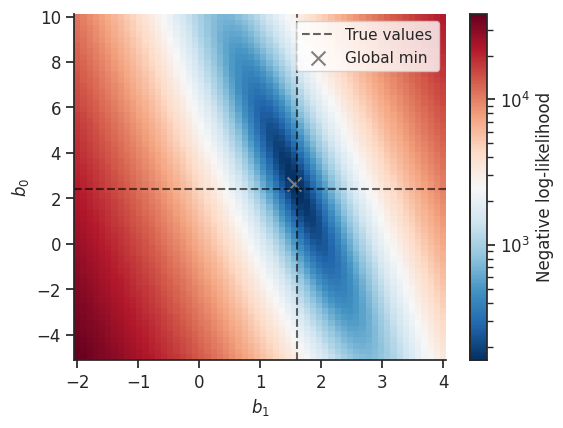

In [11]:
# plot the NLL surface (log color scale): blue is low NLL, red is high
fig, ax = plt.subplots(figsize=(6.0, 4.5))
mesh = ax.pcolormesh(b1_grid, b0_grid, nll_grid, cmap="RdBu_r", norm=LogNorm(), shading="auto")
fig.colorbar(mesh, ax=ax, label="Negative log-likelihood")
ax.axvline(b1_true, ls="--", color="k", alpha=0.6)
ax.axhline(b0_true, ls="--", color="k", alpha=0.6, label="True values")
ax.scatter(b1_grid_hat, b0_grid_hat, marker="x", color="grey", s=100, label="Global min")
ax.set(xlabel=r"$b_1$", ylabel=r"$b_0$")
ax.legend(loc="upper right")

sns.despine()
plt.show()

### Optimization

`scipy.optimize.minimize` starts from a guess and steps downhill along the slope of the NLL (with the BFGS algorithm by default) until the surface is flat. It needs far fewer evaluations than a grid and is not limited by grid spacing. However, it can stop in a local minimum, so the starting point can impact results.

In [13]:
# TODO: fit the regression with minimize
# 1. Start at x0 = [0, 0]
# 2. res_lm = minimize(nll_lm, x0, args=(x, y))
# 3. Unpack b0_hat, b1_hat from res_lm.x
# Defines: res_lm, b0_hat, b1_hat
x0_guess = [0, 0]
res_lm = minimize(nll_lm, x0_guess, args=(x, y))
b0_hat, b1_hat = res_lm.x

,True,Grid search,minimize
b0,2.4,2.627,2.659
b1,1.6,1.559,1.571


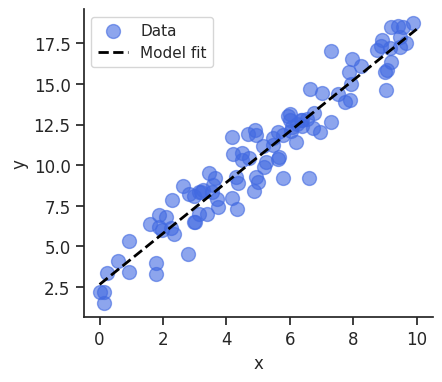

In [14]:
# compare the estimates to the true values
display(pd.DataFrame({"True": [b0_true, b1_true],
                      "Grid search": [b0_grid_hat, b1_grid_hat],
                      "minimize": [b0_hat, b1_hat]},
                     index=["b0", "b1"]).round(3))

# plot the data with the fitted line
x_line = np.linspace(0, 10, 100)
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(x, y, alpha=0.6, label="Data")
ax.plot(x_line, b0_hat + b1_hat * x_line, color="black", lw=2, linestyle='--', label="Model fit")
ax.set(xlabel="x", ylabel="y")
ax.legend()
sns.despine()
plt.show()

### A descriptive model

The estimated line is a **descriptive** model. It summarizes how $y$ changes with $x$ and makes no claim about the process that produced $y$. We could simulate $y$ only because we took $x$ as given and assumed Gaussian noise on top. Next we build a model of a cognitive process itself.

## 3. The two-armed bandit and the Rescorla-Wagner model

In a two-armed bandit task, an agent selects one of two slot machines, arm $A$ and arm $B$, for 100 trials. On each trial it picks one arm and receives 1 point or 0. Arm $A$ pays out with probability 0.8 and arm $B$ with probability 0.2, but the agent does not know these numbers and sees only the outcome of the arm it picked. To earn points it has to learn which arm is better from its own choices. The Day 2 lecture covers reinforcement learning in depth, and today we need only the simplest learning rule.

In [15]:
# task settings
n_trials = 100
p_reward = np.array([0.8, 0.2])  # payout probability for arm A and arm B

# ten sample payouts from each arm
for k, arm in enumerate(["A", "B"]):
    print(f"Arm {arm}:", (rng.random(10) < p_reward[k]).astype(int))

Arm A: [1 1 1 1 0 0 1 1 1 1]
Arm B: [1 0 0 0 0 1 0 0 0 0]


### Learning from prediction errors

The Rescorla-Wagner model keeps a value $Q_t(k)$ for each arm $k$, its current estimate of how much that arm pays. After choosing arm $c_t$ and receiving reward $r_t$, it computes a prediction error and moves the chosen arm's value toward the reward.

$$Q_{t+1}(c_t) = Q_t(c_t) + \alpha \cdot \delta_t, \qquad \delta_t = r_t - Q_t(c_t)$$

The unchosen arm keeps its value. The learning rate $\alpha \in [0, 1]$ sets how far one outcome moves the value. Both values start at 0.

In [18]:
# TODO: the Rescorla-Wagner update
# Define rw_update(Q, c, r, alpha):
#   1. Copy Q so the input array is not changed
#   2. Prediction error: delta = r - Q[c]
#   3. Move the chosen value: Q_new[c] = Q[c] + alpha * delta
#   4. Return Q_new, delta
# Check: rw_update(np.array([0.5, 0.5]), 0, 1.0, 0.3) should give [0.65, 0.5]
# Defines: rw_update(Q (2,), c int, r float, alpha float) -> (Q_new (2,), delta float)
def rw_update(Q, c, r, alpha):
    Q_new = Q.copy()
    delta = r - Q[c]
    Q_new[c] = Q[c] + alpha * delta
    return Q_new, delta

print(rw_update(np.array([.5, .5]), 0, 1.0, 0.3))

(array([0.65, 0.5 ]), np.float64(0.5))


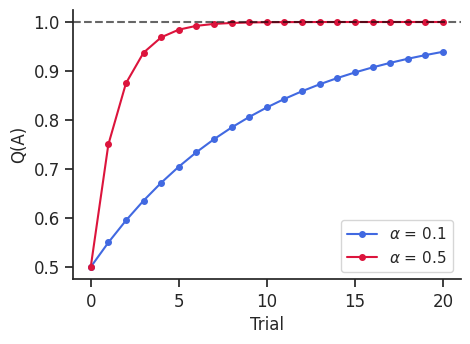

In [19]:
# Q(A) over 20 trials on which arm A is chosen and rewarded every time
fig, ax = plt.subplots(figsize=(5, 3.5))
for alpha_demo, color in [(0.1, "royalblue"), (0.5, "crimson")]:
    Q_demo = np.array([0.5, 0.5])
    trace = [Q_demo[0]]
    for t in range(20):
        Q_demo, _ = rw_update(Q_demo, 0, 1.0, alpha_demo)
        trace.append(Q_demo[0])
    ax.plot(trace, color=color, marker="o", markersize=4, label=rf"$\alpha$ = {alpha_demo}")
ax.axhline(1, ls="--", color="k", alpha=0.6)
ax.set(xlabel="Trial", ylabel="Q(A)")
ax.legend()
sns.despine()
plt.show()

### From values to choices

The softmax rule turns values into choice probabilities.

$$P(c_t = k) = \frac{\exp(\beta \, Q_t(k))}{\sum_j \exp(\beta \, Q_t(j))}$$

The inverse temperature $\beta \ge 0$ sets how strongly choices follow values. At $\beta = 0$ the agent flips a coin, and at large $\beta$ it almost always picks the higher-valued arm. With two arms, softmax reduces to $P(c_t = A) = \text{expit}\big(\beta\,(Q_t(A) - Q_t(B))\big)$, a logistic regression on the value difference.

In [21]:
# TODO: softmax
# Define softmax(Q, beta):
#   1. Subtract max(Q) from Q so large values do not overflow
#   2. Exponentiate beta * (Q - max(Q))
#   3. Divide by the sum so the probabilities add to 1
# Check: softmax(np.array([0.6, 0.4]), 5.0)[1] equals expit(5.0 * (0.4 - 0.6))
# Defines: softmax(Q (k,), beta) -> p (k,)
def softmax(Q, beta):
    numerator = np.exp(beta * (Q - np.max(Q)))
    denominator = np.sum(numerator)
    return numerator / denominator

print(softmax(np.array([.6, .4]), 5.0)[1], expit(5.0 * (0.4 - 0.6)))

0.26894142136999516 0.26894142136999516


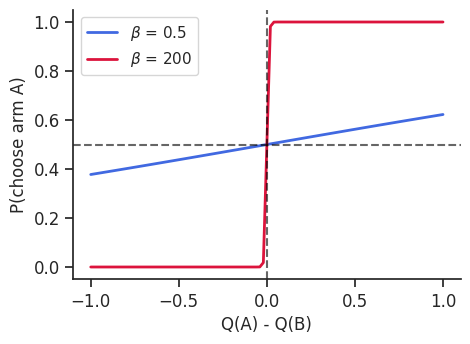

In [24]:
# probability of choosing arm A as a function of the value difference
q_diff = np.linspace(-1, 1, 101)
fig, ax = plt.subplots(figsize=(5, 3.5))
for beta_demo, color in [(.5, "royalblue"), (200, "crimson")]:
    p1 = [softmax(np.array([0.0, d]), beta_demo)[1] for d in q_diff]
    ax.plot(q_diff, p1, color=color, lw=2, label=rf"$\beta$ = {beta_demo}")
ax.axhline(0.5, ls="--", color="k", alpha=0.6)
ax.axvline(0, ls="--", color="k", alpha=0.6)
ax.set(xlabel="Q(A) - Q(B)", ylabel="P(choose arm A)")
ax.legend()
sns.despine()
plt.show()

### A generative cognitive model

Rescorla-Wagner plus softmax is a **generative** model. Given $\alpha$, $\beta$, and the task, it produces a choice on every trial, and each choice decides which outcome the agent sees next.

We can create a descriptive model of choices using a logistic regression but this learning model describes the process that produced the choices.

In [27]:
softmax([100, 100], 10)

array([0.5, 0.5])

In [31]:
# TODO: simulate one agent
# Define simulate_rw(alpha, beta, n_trials, p_reward, rng):
#   1. Allocate choices (n_trials,) int, rewards (n_trials,), Q (n_trials + 1, 2), p_choice (n_trials, 2)
#   2. Set Q[0] = 0 for both arms
#   3. For each trial t:
#      a. p_choice[t] = softmax(Q[t], beta)
#      b. Sample a choice c with rng.choice(2, p=p_choice[t])
#      c. Reward r = 1.0 if rng.random() < p_reward[c] else 0.0
#      d. Store c and r in choices[t] and rewards[t]
#      e. Q[t + 1], _ = rw_update(Q[t], c, r, alpha)
#   4. Return a dict with keys "choices", "rewards", "Q", "p_choice"
# Then set alpha_true, beta_true = 0.3, 5.0 and run
#   sim_one = simulate_rw(alpha_true, beta_true, n_trials, p_reward, rng)
# Defines: alpha_true, beta_true, sim_one with choices (100,), rewards (100,), Q (101, 2), p_choice (100, 2)
def simulate_rw(alpha, beta, n_trials, p_reward, rng):
    choices = np.zeros(n_trials, dtype=int)
    rewards = np.zeros(n_trials)
    Q = np.zeros((n_trials + 1, 2))
    p_choice = np.zeros((n_trials, 2))
    for t in range(n_trials):
        p_choice[t] = softmax(Q[t], beta)
        c = rng.choice(2, p=p_choice[t])
        r = 1.0 if rng.random() < p_reward[c] else 0.0
        choices[t] = c
        rewards[t] = r
        Q[t + 1], _ = rw_update(Q[t], c, r, alpha)
    return {"choices":choices, "rewards":rewards, "Q":Q, "p_choice":p_choice}

alpha_true, beta_true = 0.3, 5.0
sim_one = simulate_rw(alpha_true, beta_true, n_trials, p_reward, rng)


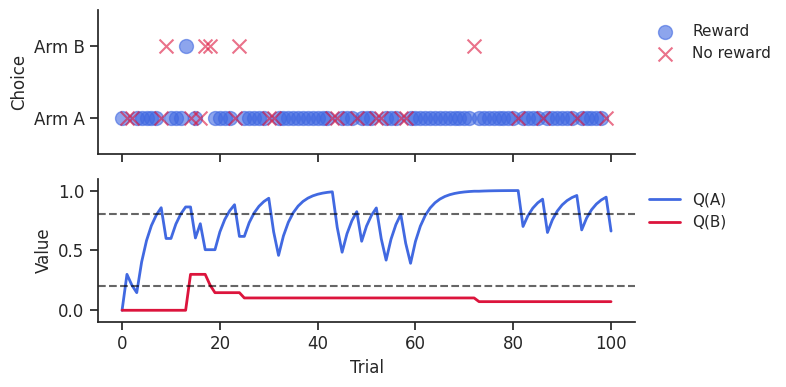

In [32]:
# choices and outcomes (top) and learned values (bottom)
trials = np.arange(n_trials)
rewarded = sim_one["rewards"] == 1
fig, axes = plt.subplots(2, 1, figsize=(8, 4), sharex=True)

axes[0].scatter(trials[rewarded], sim_one["choices"][rewarded], color="royalblue", alpha=0.6, label="Reward")
axes[0].scatter(trials[~rewarded], sim_one["choices"][~rewarded], color="crimson", alpha=0.6, marker="x", label="No reward")
axes[0].set(yticks=[0, 1], yticklabels=["Arm A", "Arm B"], ylim=(-0.5, 1.5), ylabel="Choice")
axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)

axes[1].plot(np.arange(n_trials + 1), sim_one["Q"][:, 0], color="royalblue", lw=2, label="Q(A)")
axes[1].plot(np.arange(n_trials + 1), sim_one["Q"][:, 1], color="crimson", lw=2, label="Q(B)")
for p in p_reward:
    axes[1].axhline(p, ls="--", color="k", alpha=0.6)
axes[1].set(xlabel="Trial", ylabel="Value", ylim=(-.1, 1.1))
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)

sns.despine()
plt.tight_layout()
plt.show()

### End of Part 1

We now have a model that turns two parameters into a sequence of choices. After the break we run it in reverse. Given only the choices and rewards in `sim_one`, can we recover $\alpha = 0.3$ and $\beta = 5$?

<hr width="50%">
<hr width="50%">

## 4. Fitting Rescorla-Wagner to one agent's behavior

To fit the model, we replay the agent's own choices and rewards through it. On each trial the model assigns a probability to the choice the agent made, then updates its values with the reward the agent got. Good parameters make the observed choices more likely.

We can use a similar NLL formulation, but now the likelihood is the probability of the observed choice given the current values and $\beta$.

$$\text{NLL}(\alpha, \beta) = -\sum_{t=1}^{T} \log P(c_t \mid Q_t, \beta)$$

We could call `softmax` and `rw_update` inside this function, but their numpy overhead makes the hierarchical fit (below) slower. So we write the two-arm version with plain numbers.

In [ ]:
# TODO: negative log-likelihood for Rescorla-Wagner
# Define nll_rw(params, choices, rewards):
#   1. Unpack alpha, beta from params
#   2. Turn choices and rewards into plain lists with np.asarray(...).tolist() (fast loops)
#   3. Start qA = qB = 0 and sum_nll = 0.0
#   4. For each trial (c, r):
#      a. pB = expit(beta * (qB - qA)); p = pB if c == 1 else 1 - pB
#      b. sum_nll -= np.log(p + 1e-12)
#      c. Update only the chosen value: q += alpha * (r - q)
#   5. Return sum_nll
# Check: nll_rw at [alpha_true, beta_true] is lower than at [0.9, 0.5]
# Defines: nll_rw(params (2,) [alpha, beta], choices (n,), rewards (n,)) -> float


In [ ]:
# grid search over alpha and beta
alpha_grid = np.linspace(0.01, 0.99, 40)
beta_grid = np.linspace(0.1, 15, 40)
nll_rw_grid = np.zeros((len(alpha_grid), len(beta_grid)))
for i, a in enumerate(alpha_grid):
    for j, b in enumerate(beta_grid):
        nll_rw_grid[i, j] = nll_rw([a, b], sim_one["choices"], sim_one["rewards"])

i_best, j_best = np.unravel_index(nll_rw_grid.argmin(), nll_rw_grid.shape)
alpha_grid_hat, beta_grid_hat = alpha_grid[i_best], beta_grid[j_best]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
mesh = ax.pcolormesh(beta_grid, alpha_grid, nll_rw_grid, cmap="RdBu_r", norm=LogNorm(), shading="auto")
fig.colorbar(mesh, ax=ax, label="Negative log-likelihood")
ax.axvline(beta_true, ls="--", color="k", alpha=0.6)
ax.axhline(alpha_true, ls="--", color="k", alpha=0.6, label="True values")
ax.scatter(beta_grid_hat, alpha_grid_hat, marker="x", color="grey", s=100, label="Global min")
ax.set(xlabel=r"$\beta$", ylabel=r"$\alpha$")
ax.legend(loc="upper right")
sns.despine()
plt.show()

In [ ]:
# TODO: fit Rescorla-Wagner with minimize
# 1. Start at x0 = [0.5, 1.0]; set bounds = [(1e-3, 1.0), (1e-3, 20.0)]
# 2. res_rw = minimize(nll_rw, x0, args=(sim_one["choices"], sim_one["rewards"]),
#                      method="L-BFGS-B", bounds=bounds)
# 3. Unpack alpha_hat, beta_hat from res_rw.x
# Defines: bounds, res_rw, alpha_hat, beta_hat


In [ ]:
# compare the estimates to the true values
display(pd.DataFrame({"True": [alpha_true, beta_true],
                      "Grid search": [alpha_grid_hat, beta_grid_hat],
                      "minimize": [alpha_hat, beta_hat]},
                     index=["alpha", "beta"]).round(3))

## 5. Many agents and parameter recovery

One agent tells us little, because 100 noisy choices are consistent with a range of parameter values. To check the fitting procedure, we simulate a group of agents with known parameters, fit each one, and compare the estimates to the truth. This is **parameter recovery**. If a parameter cannot be recovered from the model's own simulated data, its estimates on real data cannot be interpreted.

In [ ]:
# true parameters for a group of simulated agents
n_agents = 80
param_names = ["alpha", "beta"]
param_rng = np.random.default_rng(2026)
true_params = np.column_stack([param_rng.uniform(0.05, 0.95, n_agents),   # alpha
                               param_rng.uniform(0.5, 10, n_agents)])     # beta

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for i, name in enumerate(param_names):
    axes[i].hist(true_params[:, i], bins=15, color="royalblue", alpha=0.6, edgecolor="white")
    axes[i].set(xlabel=f"True {name}", ylabel="Agents")
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# TODO: simulate a group of agents
# Define simulate_group(params, n_trials, p_reward, rng):
#   1. For each row (alpha, beta) of params, call simulate_rw with the shared rng
#   2. Stack the choices into shape (n_agents, n_trials); do the same for rewards
#   3. Return {"choices": ..., "rewards": ...}
# Then run sim_group = simulate_group(true_params, n_trials, p_reward, rng)
# Defines: simulate_group, sim_group with choices (80, 100) and rewards (80, 100)
# (pyEM's recover() will call simulate_group)


In [ ]:
# learning curve: proportion of agents choosing the better arm (arm A) on each trial
chose_best = 1 - sim_group["choices"]
mean_best = chose_best.mean(axis=0)
sem_best = chose_best.std(axis=0, ddof=1) / np.sqrt(n_agents)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(trials, mean_best, color="royalblue", lw=2)
ax.fill_between(trials, mean_best - sem_best, mean_best + sem_best, color="royalblue", alpha=0.3)
ax.set(xlabel="Trial", ylabel="P(choose arm A)")
sns.despine()
plt.show()

In [ ]:
# TODO: fit every agent separately with MLE
# 1. mle_params = zeros (n_agents, 2); mle_nll = zeros (n_agents,)
# 2. For each agent i:
#    a. Random start: x0 = [rng.uniform(0.1, 0.9), rng.uniform(1, 10)]
#    b. minimize nll_rw on agent i's choices and rewards (method="L-BFGS-B", bounds=bounds)
#    c. Store res.x in mle_params[i] and res.fun in mle_nll[i]
# Defines: mle_params (80, 2), mle_nll (80,)


In [ ]:
# parameter recovery: true vs estimated
fig, axes = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)
for i, name in enumerate(param_names):
    plotting.plot_scatter(true_params[:, i], f"True {name}", mle_params[:, i], f"Estimated {name}",
                          ax=axes[i], s=100)
    axes[i].set_box_aspect(1)
sns.despine()
plt.show()

Look at the agents far from the dashed identity line, and at the estimates stuck on a bound ($\alpha$ at 0 or 1, $\beta$ at 20). Each agent was fit alone, using nothing but its own 100 choices.

Can we do better? Next, we let the agents share information through a group-level prior.

## 6. Hierarchical models, MAP, and EM

Maximum a posteriori (MAP) estimation adds a prior to the likelihood and finds the peak of the posterior.

$$\hat\theta = \arg\max_\theta \; P(\mathcal{D} \mid \theta)\,P(\theta) = \arg\min_\theta \; \big[\text{NLL}(\theta) - \log P(\theta)\big]$$

The prior pulls estimates toward plausible values. In a **hierarchical** model, each agent's parameters come from a group distribution $\mathcal{N}(\mu, \sigma^2)$, and that distribution is estimated from everyone's data.

### The EM algorithm

Expectation-maximization (EM) alternates two steps. The E step fits each agent by MAP under the current group prior, and the M step updates $\mu$ and $\sigma^2$ from those fits. It repeats until the estimates stop changing,We can use the [pyEM](https://github.com/shawnrhoads/pyEM) package to run this loop for us.

We start again with our descriptive regression model. While we do this, I want you to keep the standard linear mixed-effects model in mind.

In [ ]:
# simulate a regression dataset for many agents, each with their own b0 and b1
n_subj, n_obs = 50, 10
lm_true = rng.normal([1.0, 0.5], 0.5, size=(n_subj, 2))
all_data_lm = []
for i in range(n_subj):
    x_i = rng.uniform(-2, 2, n_obs)
    y_i = lm_true[i, 0] + lm_true[i, 1] * x_i + rng.normal(0, 1, n_obs)
    all_data_lm.append([x_i, y_i])

In [ ]:
# TODO: MAP objective for the regression
# Define map_lm(params, x, y, prior=None, output="npl"):
#   1. nll = nll_lm(params, x, y)
#   2. If output == "nll": return nll
#   3. If output == "all": return {"params": params, "nll": nll}
#   4. Otherwise return nll - prior.logpdf(params)   (the negative log posterior)
# Defines: map_lm -> float, or a dict with keys "params" and "nll"


In [ ]:
# TODO: fit the hierarchical regression with pyEM
# 1. lm_model = EMModel(all_data=all_data_lm, fit_func=map_lm, param_names=["b0", "b1"])
# 2. lm_fit = lm_model.fit(verbose=0)
# 3. lm_map = lm_model.outfit["params"]
# Defines: lm_model, lm_fit (lm_fit.posterior_mu has shape (2,)), lm_map (50, 2)


In [ ]:
# fit each agent alone (MLE) and compare with the hierarchical fit (MAP)
lm_mle = np.array([minimize(nll_lm, [0, 0], args=(x_i, y_i)).x for x_i, y_i in all_data_lm])

fig, axes = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)
for i, name in enumerate(["b0", "b1"]):
    ax = axes[i]
    ax.scatter(lm_true[:, i], lm_mle[:, i], color="royalblue", alpha=0.6, label="MLE")
    ax.scatter(lm_true[:, i], lm_map[:, i], color="crimson", alpha=0.6, label="MAP (EM)")
    lims = [min(lm_true[:, i].min(), lm_mle[:, i].min()), max(lm_true[:, i].max(), lm_mle[:, i].max())]
    ax.plot(lims, lims, ls="--", color="k", alpha=0.6, zorder=0)
    r_mle = np.corrcoef(lm_true[:, i], lm_mle[:, i])[0, 1]
    r_map = np.corrcoef(lm_true[:, i], lm_map[:, i])[0, 1]
    ax.annotate(f"r (MLE) = {r_mle:.2f}\nr (MAP) = {r_map:.2f}", xy=(0.05, 0.95),
                xycoords="axes fraction", va="top", fontsize=11)
    ax.set(xlabel=f"True {name}", ylabel=f"Estimated {name}")
    ax.set_box_aspect(1)
axes[1].legend(loc="lower right")
sns.despine()
plt.show()

### The link to mixed-effects regression

This hierarchical fit is a mixed-effects regression. The group means $\mu$ correspond to the fixed effects, and each agent's MAP estimate corresponds to the fixed effects plus that agent's random effects. Both methods pull noisy agents toward the group. We can check the first claim with `statsmodels`.

In [ ]:
# fit the same data with a mixed-effects model (random intercepts and slopes)
df_lm = pd.DataFrame([(i, xv, yv) for i, (x_i, y_i) in enumerate(all_data_lm) for xv, yv in zip(x_i, y_i)],
                     columns=["agent", "x", "y"])
mixed = MixedLM.from_formula("y ~ x", df_lm, groups="agent", re_formula="~x").fit()

display(pd.DataFrame({"MixedLM fixed effects": mixed.fe_params.values,
                      "pyEM group mean": lm_fit.posterior_mu},
                     index=["b0", "b1"]).round(3))

## 7. Hierarchical fitting of Rescorla-Wagner with pyEM

pyEM's group prior is Gaussian, so each parameter has to live on an unbounded scale. The optimizer searches over unbounded values $a$ and $b$, and we map them into the allowed ranges with $\alpha = \text{expit}(a)$ and $\beta = 20 \cdot \text{expit}(b)$. The fitting function below mirrors `map_lm`, and only the transforms are new.

In [ ]:
def to_alpha(a):
    return expit(a)          # any number -> (0, 1)

def to_beta(b):
    return 20 * expit(b)     # any number -> (0, 20)

def map_rw(params, choices, rewards, prior=None, output="npl"):
    alpha, beta = to_alpha(params[0]), to_beta(params[1])
    nll = nll_rw([alpha, beta], choices, rewards)
    if output == "nll":
        return nll
    if output == "all":
        return {"params": [alpha, beta], "nll": nll}
    npl = nll - prior.logpdf(params)
    return npl

In [ ]:
# TODO: fit the hierarchical Rescorla-Wagner model with pyEM
# 1. all_data_rw = [[c, r] for c, r in zip(sim_group["choices"], sim_group["rewards"])]
# 2. rw_model = EMModel(all_data=all_data_rw, fit_func=map_rw, param_names=param_names,
#                       param_xform=[to_alpha, to_beta])
# 3. rw_fit = rw_model.fit(verbose=0)
# 4. rw_map = rw_model.outfit["params"]   (already on the alpha and beta scales)
# Defines: all_data_rw (80 rows), rw_model, rw_fit, rw_map (80, 2)


In [ ]:
# same agents, same data: MLE (each agent alone) vs MAP (hierarchical)
fig, axes = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)
for i, name in enumerate(param_names):
    ax = axes[i]
    ax.scatter(true_params[:, i], mle_params[:, i], color="royalblue", alpha=0.6, label="MLE")
    ax.scatter(true_params[:, i], rw_map[:, i], color="crimson", alpha=0.6, label="MAP (EM)")
    lims = [min(true_params[:, i].min(), mle_params[:, i].min()), max(true_params[:, i].max(), mle_params[:, i].max())]
    ax.plot(lims, lims, ls="--", color="k", alpha=0.6, zorder=0)
    r_mle = np.corrcoef(true_params[:, i], mle_params[:, i])[0, 1]
    r_map = np.corrcoef(true_params[:, i], rw_map[:, i])[0, 1]
    ax.annotate(f"r (MLE) = {r_mle:.2f}\nr (MAP) = {r_map:.2f}", xy=(0.05, 0.95),
                xycoords="axes fraction", va="top", fontsize=11)
    ax.set(xlabel=f"True {name}", ylabel=f"Estimated {name}")
    ax.set_box_aspect(1)
axes[1].legend(loc="lower right")
sns.despine()
plt.show()

### Parameter recovery using pyEM

We can use the `recover()` method to run the whole check for us. It simulates new data from a set of true parameters, fits the model, and returns the estimates. `recover()` also replaces the data and fit stored on the model that calls it, so we give it a fresh `EMModel` object.

In [ ]:
# TODO: parameter recovery with pyEM
# 1. rw_rec_model = EMModel(all_data=None, fit_func=map_rw, param_names=param_names,
#                           param_xform=[to_alpha, to_beta], simulate_func=simulate_group)
# 2. rw_recovery = rw_rec_model.recover(true_params, pr_inputs=["choices", "rewards"],
#                                       n_trials=n_trials, p_reward=p_reward, rng=rng)
# 3. fig = rw_rec_model.plot_recovery(rw_recovery)
# Defines: rw_rec_model, rw_recovery (keys include "true_params", "estimated_params", "correlation")


## 8. Model comparison

A model with more parameters almost always fits better, so fit alone cannot pick a model. Information criteria add a penalty for each of the $k$ parameters, given $n$ trials.

$$\text{AIC} = 2k + 2\,\text{NLL}, \qquad \text{BIC} = k \ln n + 2\,\text{NLL}$$

Lower is better for both. The log model evidence (LME) is the probability of the data under the model with its parameters integrated out, approximated here from the hierarchical fit, and higher is better. WAIC asks the same question with samples from the full posterior, which needs sampling tools such as Stan or PyMC, so we do not compute it today.

### A competitor: noisy win-stay-lose-shift

Win-stay-lose-shift (WSLS) keeps no values. After a reward it repeats its last choice, and after no reward it switches. With probability $\epsilon$ it ignores the rule and picks at random, so it follows the rule with probability $1 - \epsilon/2$. It has one parameter, against two for Rescorla-Wagner.

In [ ]:
def wsls_nll(params, choices, rewards):
    eps = params[0]
    choices, rewards = np.asarray(choices).tolist(), np.asarray(rewards).tolist()
    sum_nll = -np.log(0.5)                      # the first choice is a coin flip
    for t in range(1, len(choices)):
        rule = choices[t - 1] if rewards[t - 1] == 1 else 1 - choices[t - 1]
        p = 1 - eps / 2 if choices[t] == rule else eps / 2
        sum_nll -= np.log(p + 1e-12)
    return sum_nll


def map_wsls(params, choices, rewards, prior=None, output="npl"):
    eps = expit(params[0])                    # any number -> (0, 1)
    nll = wsls_nll([eps], choices, rewards)
    if output == "nll":
        return nll
    if output == "all":
        return {"params": [eps], "nll": nll}
    return nll - prior.logpdf(params)


# fit WSLS to every agent separately (MLE), as we did for Rescorla-Wagner above
wsls_nll_hat = np.zeros(n_agents)
for i in range(n_agents):
    res = minimize(wsls_nll, [0.5], args=(sim_group["choices"][i], sim_group["rewards"][i]),
                   method="L-BFGS-B", bounds=[(1e-3, 1.0)])
    wsls_nll_hat[i] = res.fun

In [ ]:
# TODO: AIC and BIC for each agent
# 1. n_obs_rw = sim_group["choices"].shape[1]   (trials per agent, read from the data)
# 2. aic_rw = 2 * 2 + 2 * mle_nll;   aic_wsls = 2 * 1 + 2 * wsls_nll_hat
# 3. bic_rw = 2 * np.log(n_obs_rw) + 2 * mle_nll;   bic_wsls = 1 * np.log(n_obs_rw) + 2 * wsls_nll_hat
# 4. Print each one summed across agents
# Defines: n_obs_rw, aic_rw, aic_wsls, bic_rw, bic_wsls (each (80,))


In [ ]:
# per-agent BIC difference: positive values favor Rescorla-Wagner
delta_bic = bic_wsls - bic_rw
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.hist(delta_bic, bins=20, color="royalblue", alpha=0.6, edgecolor="white")
ax.axvline(0, ls="--", color="k", alpha=0.6)
ax.set(xlabel="BIC(WSLS) - BIC(RW)", ylabel="Agents",
       title=f"{np.mean(delta_bic > 0):.0%} of agents favor Rescorla-Wagner")
sns.despine()
plt.show()

In [ ]:
# TODO: hierarchical model comparison with pyEM
# 1. wsls_model = EMModel(all_data=all_data_rw, fit_func=map_wsls, param_names=["epsilon"],
#                         param_xform=[expit])
# 2. wsls_model.fit(verbose=0)
# 3. comparison = ModelComparison([rw_model, wsls_model], ["RW", "WSLS"])
# 4. comparison.compare(bicint_kwargs={"nsamples": 200, "func_output": "all", "nll_key": "nll"})
# Defines: wsls_model, comparison (compare() returns a table with LME and integrated BIC)


These data came from Rescorla-Wagner, so it should win. It would be a red flag if model comparison picked WSLS as the winning model here.

If we simulate from WSLS, does the comparison pick WSLS? See the potential group projects below for this exercise.

## Summary

Each example used the following recipe: (1) Write down how the model assigns probability to data, then (2) search for the parameters that make the data most probable.

Parameter recovery allows us to test our model and task paradigm. Ideally for any real study, you should design your task, simulate, recover, and compare plausible models to validate your task and models before collecting any data and interpreting any parameters.

No model is perfect, but we can still learn a lot from them!

<img src="https://github.com/Center-for-Computational-Psychiatry/course_nycpw/blob/main/img/meme-all-models-are-wrong.png?raw=1" alt="meme-all-models-are-wrong">

## Group project proposals

**1. Asymmetric learning.** Give Rescorla-Wagner separate learning rates for positive and negative prediction errors ($\alpha^+$ and $\alpha^-$). This lets the model express optimistic or pessimistic updating, and the group can test whether 100 trials are enough to tell the two rates apart. *First step:* copy `rw_update` and `nll_rw` into three-parameter versions that pick the learning rate by the sign of $\delta$, then run `recover()` with $\alpha^+ \neq \alpha^-$.

**2. Same pipeline, new task.** Repeat today's simulate, fit, and recover pipeline with Rescorla-Wagner on either (i) a reversal learning task, where the payout probabilities swap halfway through, or (ii) a four-armed bandit. Compare the recovery correlations with today's. *First step:* replace `p_reward` with an `(n_trials, n_arms)` schedule inside `simulate_rw`, and generalize `nll_rw` to $k$ arms using `softmax`.

**3. Model identifiability.** Simulate data from win-stay-lose-shift, Rescorla-Wagner, and a Bayesian learner (a Beta-Bernoulli belief about each arm, with softmax on the posterior means) on a two- or three-armed bandit. Fit all three models to every dataset and count how often each one wins. *First step:* write `simulate` and `map` functions for the Bayesian learner (see the Bayesian Inference session), then try to implement Model Comparison by yourself and verify by running `ModelComparison(...).identify(mi_inputs=["choices", "rewards"])` and `plot_identifiability(metric="LME", cmap="RdBu_r")`.

## Additional resources

- Wilson, R. C., & Collins, A. G. (2019). Ten simple rules for the computational modeling of behavioral data. *eLife, 8*, e49547. https://elifesciences.org/articles/49547
- Daw, N. D. (2011). Trial-by-trial data analysis using computational models. In *Decision making, affect, and learning: Attention and performance XXIII*. https://www.princeton.edu/~ndaw/d10.pdf
- Rhoads, S. A. & Gan, L. (2022). Computational models of human social behavior and neuroscience: An open educational course and Jupyter Book to advance computational training. *Journal of Open Source Education, 5*(47), 146. https://shawnrhoadsphd.com/gu-psyc-347
- Rhoads, S. A. (2023). pyEM: Expectation Maximization with MAP estimation in Python. doi: 10.5281/zenodo.10415396. https://github.com/shawnrhoads/pyEM
    - pyEM Documentation: https://shawnrhoadsphd.com/pyEM